# SPC: ¿señal o ruido? El gráfico XmR

**Avanzado · Jornada 4 · Bloque 4.2 · diapositivas sube-12, embudo, dos-variaciones, xmr, reglas, fases-objetivos, ejercicio-xmr y doce-ruido**

El tiempo medio de reparación ha subido un 12 %: ¿hay que actuar? El cuaderno construye el gráfico
XmR paso a paso, mide el precio de las reglas de detección y separa límites de objetivos.

**Cómo usarlo.** En Google Colab: menú *Entorno de ejecución → Ejecutar todo* (*Runtime → Run all*). La primera vez tarda un poco: descarga los datos del curso. En Jupyter: *Ejecutar → Ejecutar todo*.

El código está a la vista. **Si no programas**, lee los comentarios, cambia los valores marcados con `# ←` y vuelve a ejecutar. **Si programas**, completa los huecos marcados con `# COMPLETAD`.

In [1]:
# Preparación: busca los datos del curso, instala lo que falte en Colab y carga el estilo.
# No hace falta tocar nada.
import importlib.util
import subprocess
import sys
from pathlib import Path


def buscar_proyecto():
    """La carpeta que contiene datos/avanzado y scripts/estilo.py."""
    aqui = Path.cwd()
    for carpeta in (aqui, *aqui.parents):
        if (carpeta / "scripts" / "estilo.py").exists() and (carpeta / "datos" / "avanzado").exists():
            return carpeta
    if "google.colab" in sys.modules:  # en Colab: descarga una vez el material público del curso
        destino = Path("/content/curso-analitica-cuadernos")
        if not destino.exists():
            subprocess.run(["git", "clone", "--quiet", "--depth", "1",
                            "https://github.com/castrorbea/curso-analitica-cuadernos.git", str(destino)], check=True)
        return destino
    raise FileNotFoundError("No encuentro los datos del curso: abre este cuaderno desde cuadernos/avanzado/.")


PROYECTO = buscar_proyecto()
DATOS = PROYECTO / "datos" / "avanzado"
for ruta in (PROYECTO / "scripts", PROYECTO / "cuadernos" / "avanzado"):
    if str(ruta) not in sys.path:
        sys.path.insert(0, str(ruta))
if "google.colab" in sys.modules and importlib.util.find_spec("h3") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "h3"], check=True)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import bici    # rutas, descarga de la telemetría completa y hora local
import estilo  # colores, letra y formato numérico español del curso

# estilo.py fija el modo sin pantalla de matplotlib (para guardar PNG); en el cuaderno, los gráficos se ven.
get_ipython().run_line_magic("matplotlib", "inline")
pd.set_option("display.max_columns", 30)
print("Listo. Datos en", DATOS)


Listo. Datos en /Users/acastro/dev/cursos-analitica-datos/datos/avanzado


## La pregunta

Septiembre de 2026. El tiempo medio que BiciCiudad tarda en reparar una bici averiada ha pasado de
**46,3 horas en agosto a 51,9 en septiembre: un 12 % más**. El dato llega al comité con una flecha
roja. ¿Reunión con el taller esta semana, esperar a octubre u otra cosa?

Este cuaderno contesta con el control estadístico de procesos (SPC): primero el embudo de Deming
(qué pasa si se corrige el ruido), después el gráfico XmR, las reglas de detección, las fases y los
objetivos, y por último el ejercicio de los tres indicadores.

> **Mensaje clave del bloque:** la subida del 12 % de la pregunta inicial está dentro de los
> límites; investigarla habría sido trabajo sin retorno.

## 1. Cargar y mirar los datos

`indicadores/indicadores_mensuales.csv`: 36 meses (octubre de 2023 a septiembre de 2026) de tres
indicadores de BiciCiudad: el tiempo medio de reparación (`tmr_horas`), la disponibilidad de las
estaciones (`disponibilidad_pct`, % del tiempo operativas) y las bicis operativas
(`bicis_operativas_pct`, % de la flota fuera del taller).

In [2]:
# Tablas con coma decimal y tres ayudas de formato en español.
pd.set_option("display.float_format", lambda x: estilo.num(x, 2))


def n(x, decimales=0):
    """Número en español: 1.234,5, con el signo menos tipográfico (−)."""
    return estilo.num(x, decimales).replace("-", "−")


def pct(x, decimales=1):
    """Proporción como porcentaje: 0,133 → «13,3 %»."""
    return n(100 * x, decimales) + " %"


def fecha(t):
    """Fecha corta en español: 22-12-2025."""
    t = pd.Timestamp(t)
    return f"{t.day}-{t.month}-{t.year}"


indicadores = pd.read_csv(DATOS / "indicadores" / "indicadores_mensuales.csv")
indicadores["mes"] = pd.PeriodIndex(indicadores["mes"], freq="M")
indicadores = indicadores.set_index("mes")

agosto = indicadores.loc[pd.Period("2026-08", "M"), "tmr_horas"]
septiembre = indicadores.loc[pd.Period("2026-09", "M"), "tmr_horas"]
subida = septiembre / agosto - 1
print(f"Tiempo medio de reparación: {n(agosto, 1)} h en agosto → {n(septiembre, 1)} h en septiembre "
      f"({'+' if subida > 0 else ''}{pct(subida)})")
indicadores.tail(6)

Tiempo medio de reparación: 46,3 h en agosto → 51,9 h en septiembre (+12,1 %)


,tmr_horas,disponibilidad_pct,bicis_operativas_pct
mes,,,
2026-04,"51,90","97,10","91,00"
2026-05,"60,80","96,40","91,00"
2026-06,"50,20","96,80","91,20"
2026-07,"47,70","97,40","91,20"
2026-08,"46,30","97,20","92,30"
2026-09,"51,90","97,00","92,70"


Una variación de un mes a otro, sola, no dice nada. Hace falta saber **cuánto se mueve el indicador
cuando no pasa nada**. Antes de calcularlo, veamos qué pasa si se reacciona a cada movimiento.

## 2. El embudo de Deming: corregir el ruido duplica la variación

W. E. Deming lo contaba en *Out of the Crisis* (1986): se deja caer una canica por un embudo sobre
una diana y se marca dónde cae. `embudo/caidas.csv` simula 50 caídas con cuatro reglas y **el mismo
ruido en las cuatro, caída a caída**: solo cambia la regla.

1. No tocar el embudo.
2. Tras cada caída, mover el embudo lo contrario del error, desde donde está (la del «sentido común»).
3. Poner el embudo en el punto opuesto al error, medido desde el blanco.
4. Poner el embudo encima de la última caída.

In [3]:
caidas = pd.read_csv(DATOS / "embudo" / "caidas.csv")
# Distancia al cuadrado de cada caída al blanco, que está en (0, 0).
caidas["distancia2"] = caidas["x"] ** 2 + caidas["y"] ** 2
distancia2 = caidas.groupby("regla")["distancia2"].mean()
for regla, valor in distancia2.items():
    print(f"Regla {regla}: distancia² media al blanco {n(valor, 2)}")
print(f"Regla 2 frente a regla 1: × {n(distancia2[2] / distancia2[1], 2)}")

Regla 1: distancia² media al blanco 2,03
Regla 2: distancia² media al blanco 4,32
Regla 3: distancia² media al blanco 78,20
Regla 4: distancia² media al blanco 9,00
Regla 2 frente a regla 1: × 2,13


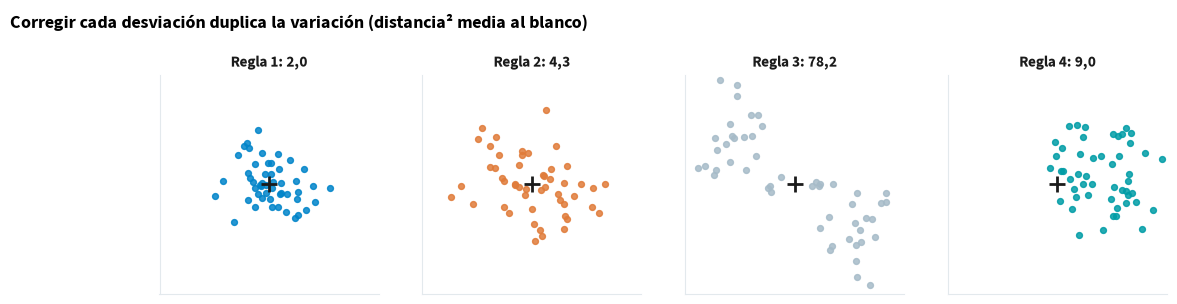

In [4]:
fig, ejes = plt.subplots(1, 4, figsize=(13, 3.6))
colores = {1: estilo.AZUL, 2: estilo.NARANJA, 3: estilo.GRIS, 4: estilo.TURQUESA}
for ax, (regla, grupo) in zip(ejes, caidas.groupby("regla")):
    ax.scatter(grupo["x"], grupo["y"], s=18, color=colores[regla], alpha=0.85)
    ax.scatter([0], [0], marker="+", s=120, color=estilo.TEXTO, linewidth=2)
    limite = max(5, grupo[["x", "y"]].abs().max().max() * 1.05)
    ax.set_xlim(-limite, limite)
    ax.set_ylim(-limite, limite)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"Regla {regla}: {n(distancia2[regla], 1)}", fontsize=11, loc="center", pad=6)
fig.suptitle("Corregir cada desviación duplica la variación (distancia² media al blanco)",
             x=0.01, ha="left", fontsize=13, weight="bold")
plt.show()

Ojo a las escalas: las reglas 3 y 4 se van tan lejos que su diana es mucho más grande.

**Por qué la regla 2 duplica la varianza.** Si la caída *k* tiene un error aleatorio *eₖ*, con la
regla 2 el embudo acaba en −*eₖ* y la caída siguiente cae en *eₖ₊₁* − *eₖ*: la suma de dos ruidos
independientes, con el doble de varianza. Corregir el ruido es meter más ruido. La simulación da
× 2,13; la teoría, × 2. La regla 3 oscila cada vez más lejos y la 4 es un paseo aleatorio.

Esa es la primera trampa del bloque: **corregir el ruido**. Las dos clases de variación:

| | Variación común | Causa especial |
| --- | --- | --- |
| Qué es | Muchas causas pequeñas, siempre presentes | Algo concreto, con nombre y fecha |
| Qué hacer | No reaccionar a cada punto; si el nivel no gusta, cambiar el proceso | Investigarla y quitarla (o quedársela, si es buena) |
| En BiciCiudad | Casi todos los meses | Mayo de 2026, el retraso de los recambios |

## 3. El gráfico XmR, paso a paso

El gráfico de valores individuales y rango móvil (XmR) es el más útil para indicadores mensuales:
pocos datos, uno por mes, sin subgrupos. Lo construimos con la disponibilidad de las estaciones en
los 27 meses en que no cambió nada importante (octubre de 2023 a diciembre de 2025).

In [5]:
disponibilidad = indicadores.loc["2023-10":"2025-12", "disponibilidad_pct"]

# 1. La media de los 27 meses.
media = disponibilidad.mean()
# 2. El rango móvil: cuánto cambia cada mes frente al anterior, en valor absoluto. Y su media.
rango_movil = disponibilidad.diff().abs()
rango_movil_medio = rango_movil.mean()
# 3. Los límites: media ± 2,66 × rango móvil medio. (2,66 = 3 / 1,128: tres sigmas estimadas
#    con el rango móvil.) El rango móvil tiene su propio límite superior: 3,268 × su media.
limite_inferior = media - 2.66 * rango_movil_medio
limite_superior = media + 2.66 * rango_movil_medio
limite_rango = 3.268 * rango_movil_medio

print(f"{len(disponibilidad)} meses. Media {n(media, 1)} %; rango móvil medio {n(rango_movil_medio, 2)} puntos")
print(f"Límites: de {n(limite_inferior, 1)} a {n(limite_superior, 1)} %. "
      f"Límite del rango móvil: {n(limite_rango, 2)} puntos")
fuera = disponibilidad[(disponibilidad < limite_inferior) | (disponibilidad > limite_superior)]
print(f"Meses fuera de los límites: {len(fuera)}; saltos por encima del límite del rango móvil: "
      f"{int((rango_movil > limite_rango).sum())}")

27 meses. Media 95,1 %; rango móvil medio 0,70 puntos
Límites: de 93,3 a 97,0 %. Límite del rango móvil: 2,29 puntos
Meses fuera de los límites: 0; saltos por encima del límite del rango móvil: 0


Comprobad un límite a mano: 95,12 + 2,66 × 0,70 = 96,98 ≈ 97,0 %. Y el ¿por qué no usar la
desviación típica de toda la serie? Porque si hay un cambio, la desviación global lo absorbe e infla
los límites. El rango móvil, que solo mira de un mes al siguiente, se contamina mucho menos.

Las dos mitades del XmR: arriba, los valores; abajo, el rango móvil, que en la diapositiva se
quedó fuera.

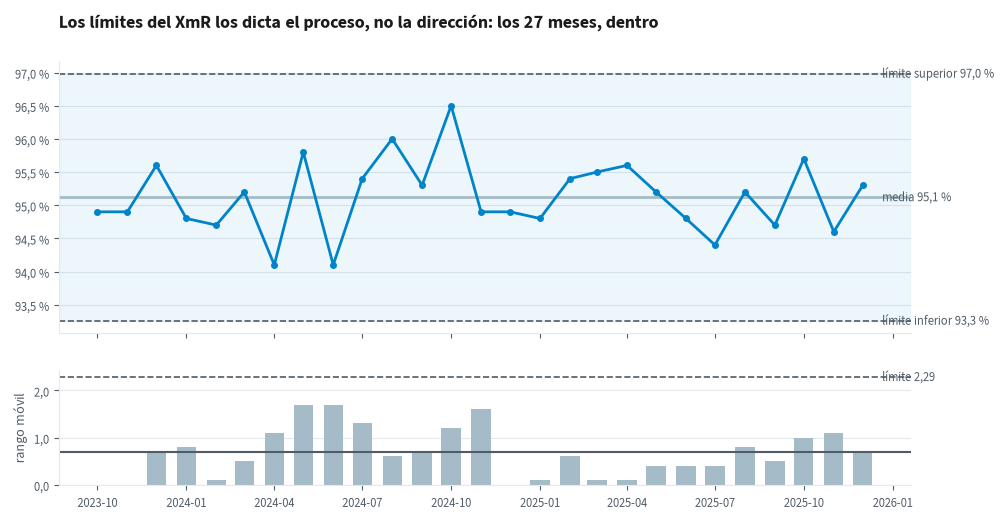

In [6]:
meses = disponibilidad.index.to_timestamp()
fig, (ax, ax_rm) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True, gridspec_kw={"height_ratios": [2.4, 1]})
ax.axhspan(limite_inferior, limite_superior, color=estilo.AZUL, alpha=0.07)
for valor in (limite_inferior, limite_superior):
    ax.axhline(valor, color=estilo.TEXTO_2, linestyle="--", linewidth=1.2)
ax.axhline(media, color=estilo.GRIS, linewidth=2)
ax.plot(meses, disponibilidad, color=estilo.AZUL, marker="o", markersize=4)
for valor, texto in ((limite_superior, "límite superior"), (media, "media"), (limite_inferior, "límite inferior")):
    ax.text(meses[-1] + pd.Timedelta(days=20), valor, f"{texto} {n(valor, 1)} %", va="center",
            color=estilo.TEXTO_2, fontsize=9)
estilo.formato_eje(ax, decimales=1, sufijo=" %")
ax.set_title("Los límites del XmR los dicta el proceso, no la dirección: los 27 meses, dentro")
ax_rm.bar(meses, rango_movil, width=20, color=estilo.GRIS)
ax_rm.axhline(rango_movil_medio, color=estilo.TEXTO_2, linewidth=1.5)
ax_rm.axhline(limite_rango, color=estilo.TEXTO_2, linestyle="--", linewidth=1.2)
ax_rm.text(meses[-1] + pd.Timedelta(days=20), limite_rango, f"límite {n(limite_rango, 2)}", va="center",
           color=estilo.TEXTO_2, fontsize=9)
ax_rm.set_ylabel("rango móvil")
estilo.formato_eje(ax_rm, decimales=1)
plt.show()

Usaremos esta construcción muchas veces, así que la guardamos en una función de cuatro líneas.

In [7]:
def limites_xmr(serie):
    """Media, rango móvil medio y límites naturales: media ± 2,66 × rango móvil medio."""
    media = serie.mean()
    rango_movil_medio = serie.diff().abs().mean()
    return media, rango_movil_medio, media - 2.66 * rango_movil_medio, media + 2.66 * rango_movil_medio

## 4. Reglas de detección: cada regla de más compra falsas alarmas

Además del punto fuera de los límites, las reglas clásicas de Western Electric (1956) y de Nelson
(1984) buscan formas de cambio en las que ningún punto se sale:

1. **Un punto fuera** de los límites de tres sigmas.
2. **Racha de 8**: ocho seguidos al mismo lado de la media.
3. **Tendencia de 6**: seis puntos seguidos subiendo (o bajando), es decir, cinco subidas seguidas.
4. **Dos de tres** seguidos más allá de dos sigmas, del mismo lado.

Sigma es el rango móvil medio entre 1,128. Las aplicamos al tiempo de reparación con los límites
del contrato anterior (fase I de octubre de 2023 a marzo de 2025), para ver qué dicen del cambio de
contrato de abril de 2025.

In [8]:
def reglas_deteccion(serie, media, sigma):
    """Una columna por regla: True en los puntos que la hacen saltar."""
    z = (serie - media) / sigma
    lado = np.sign(z)
    sube = np.sign(serie.diff())
    return pd.DataFrame({
        "1 · punto fuera": z.abs() > 3,
        "2 · racha de 8": lado.rolling(8).sum().abs() == 8,
        "3 · tendencia de 6": sube.rolling(5).sum().abs() == 5,   # seis puntos: cinco subidas
        "4 · dos de tres": ((z > 2).astype(int).rolling(3).sum() >= 2) | ((z < -2).astype(int).rolling(3).sum() >= 2),
    })


reparacion = indicadores["tmr_horas"]
media_ant, rm_ant, _, _ = limites_xmr(reparacion.loc["2023-10":"2025-03"])
saltan = reglas_deteccion(reparacion, media_ant, rm_ant / 1.128)
for regla in saltan.columns:
    meses_alarma = [str(m) for m in saltan.index[saltan[regla]]]
    print(f"{regla}: {', '.join(meses_alarma) if meses_alarma else 'ninguno'}")

1 · punto fuera: 2025-09, 2026-07, 2026-08
2 · racha de 8: 2025-11, 2025-12, 2026-01, 2026-02, 2026-03, 2026-04
3 · tendencia de 6: ninguno
4 · dos de tres: 2025-05, 2025-06, 2025-07, 2025-08, 2025-09, 2025-10, 2025-11, 2025-12, 2026-01, 2026-02, 2026-03, 2026-04, 2026-07, 2026-08, 2026-09


Con los límites antiguos, el contrato nuevo salta por la **racha de 8** (ocho meses seguidos por
debajo de la media anterior) y por puntos bajo el límite inferior: es una señal, y buena.

**¿Por qué no usar siempre las cuatro?** Con datos independientes y un proceso estable, la regla 1
sola da una falsa alarma cada 370 puntos de media (1 / 0,0027). Cada regla añadida es otra
oportunidad de que salte por azar. Lo medimos con una simulación: miles de series de ruido puro, y
para cada combinación de reglas, cuántos puntos pasan de media hasta la primera falsa alarma.

In [9]:
from numpy.lib.stride_tricks import sliding_window_view as ventanas

N_SERIES, LARGO = 2000, 4000   # ← series de ruido puro (media 0, sigma 1) y puntos de cada una
azar = np.random.default_rng(2026)
x = azar.normal(size=(N_SERIES, LARGO))

# Cada regla, para todas las series a la vez (True donde salta).
regla1 = np.abs(x) > 3
regla2 = np.zeros_like(regla1)
regla2[:, 7:] = np.abs(ventanas(np.sign(x), 8, axis=1).sum(axis=2)) == 8
regla3 = np.zeros_like(regla1)   # seis puntos seguidos subiendo (o bajando): cinco diferencias del mismo signo
regla3[:, 5:] = np.abs(ventanas(np.sign(np.diff(x, axis=1)), 5, axis=1).sum(axis=2)) == 5
regla4 = np.zeros_like(regla1)
regla4[:, 2:] = ((ventanas(x > 2, 3, axis=1).sum(axis=2) >= 2)
                 | (ventanas(x < -2, 3, axis=1).sum(axis=2) >= 2))


def puntos_hasta_falsa_alarma(alarmas):
    """Media de la posición de la primera alarma de cada serie (ARL sin cambio)."""
    return (alarmas.argmax(axis=1) + 1).mean()


combinaciones = {"Regla 1 sola": regla1, "Reglas 1 y 2": regla1 | regla2,
                 "Reglas 1, 2 y 3": regla1 | regla2 | regla3, "Las cuatro": regla1 | regla2 | regla3 | regla4}
arl_reglas = pd.Series({nombre: puntos_hasta_falsa_alarma(a) for nombre, a in combinaciones.items()})
for nombre, valor in arl_reglas.items():
    print(f"{nombre}: una falsa alarma cada {n(valor)} puntos")
print(f"Con las cuatro, la falsa alarma llega {n(arl_reglas.iloc[0] / arl_reglas.iloc[-1], 1)} veces antes")

Regla 1 sola: una falsa alarma cada 374 puntos
Reglas 1 y 2: una falsa alarma cada 154 puntos
Reglas 1, 2 y 3: una falsa alarma cada 113 puntos
Las cuatro: una falsa alarma cada 96 puntos
Con las cuatro, la falsa alarma llega 3,9 veces antes


En un indicador mensual, la regla 1 sola da una falsa alarma cada treinta años; con las cuatro, cada
ocho. Y si se vigilan cincuenta indicadores a la vez, alguna saltará todos los meses. Criterio
práctico: **pocas reglas, decididas antes y escritas en la ficha del indicador**. Lo que no vale es
mirar el gráfico, ver algo raro y buscar después la regla que lo justifique.

## 5. Fases y objetivos: los límites los fija el proceso; los objetivos, la dirección

En abril de 2025 entró el contrato nuevo de mantenimiento: un cambio de proceso documentado. Los
doce meses siguientes (abril de 2025 a marzo de 2026) son la **fase I**, de la que salen los
límites; después, en la **fase II**, se congelan y se vigila con ellos. El objetivo de la dirección,
un 95 % de bicis operativas, es **inventado** para el ejemplo.

Fase I (abril de 2025 a marzo de 2026): media 91,0 %, límites 89,6 y 92,5 %
Fase II, meses fuera: 2026-09 (92,7 %)


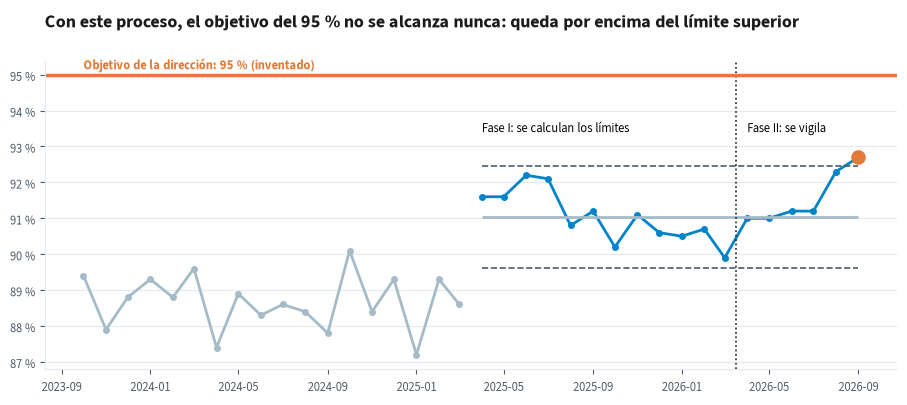

In [10]:
OBJETIVO = 95.0   # ← objetivo de la dirección (inventado para el ejemplo)

operativas = indicadores["bicis_operativas_pct"]
fase1 = operativas.loc["2025-04":"2026-03"]
fase2 = operativas.loc["2026-04":]
media_f1, _, lci_f1, lcs_f1 = limites_xmr(fase1)
print(f"Fase I (abril de 2025 a marzo de 2026): media {n(media_f1, 1)} %, límites {n(lci_f1, 1)} y {n(lcs_f1, 1)} %")
senales = fase2[(fase2 > lcs_f1) | (fase2 < lci_f1)]
print("Fase II, meses fuera:", ", ".join(f"{m} ({n(v, 1)} %)" for m, v in senales.items()) or "ninguno")

meses = operativas.index.to_timestamp()
nuevo = meses >= pd.Timestamp("2025-04-01")
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(meses[~nuevo], operativas[~nuevo], color=estilo.GRIS, marker="o", markersize=4, label="contrato anterior")
ax.plot(meses[nuevo], operativas[nuevo], color=estilo.AZUL, marker="o", markersize=4)
desde, hasta = pd.Timestamp("2025-04-01"), meses[-1]
for valor in (lci_f1, lcs_f1):
    ax.hlines(valor, desde, hasta, color=estilo.TEXTO_2, linestyle="--", linewidth=1.2)
ax.hlines(media_f1, desde, hasta, color=estilo.GRIS, linewidth=2)
ax.axvline(pd.Timestamp("2026-04-01") - pd.Timedelta(days=15), color=estilo.TEXTO, linestyle=":", linewidth=1.2)
ax.text(desde, 93.4, "Fase I: se calculan los límites", fontsize=9)
ax.text(pd.Timestamp("2026-04-01"), 93.4, "Fase II: se vigila", fontsize=9)
ax.axhline(OBJETIVO, color=estilo.NARANJA, linewidth=2.5)
ax.text(meses[0], OBJETIVO + 0.15, f"Objetivo de la dirección: {n(OBJETIVO)} % (inventado)",
        color=estilo.NARANJA, weight="bold", fontsize=9)
ax.scatter(senales.index.to_timestamp(), senales, s=90, color=estilo.NARANJA, zorder=5)
estilo.formato_eje(ax, sufijo=" %")
ax.set_title("Con este proceso, el objetivo del 95 % no se alcanza nunca: queda por encima del límite superior")
plt.show()

Dos lecturas:

- **Septiembre de 2026**, justo por encima del límite superior: una señal, aunque sea buena. Merece la
  pregunta «¿qué ha cambiado?», para mantenerlo.
- **El objetivo del 95 %** queda fuera de los límites: con este proceso no se alcanza nunca. Exigirlo
  mes a mes sin cambiar nada solo produce frustración y maquillaje del indicador (la ley de Goodhart
  del curso conceptual). Si el objetivo cae fuera de los límites, la conversación no es «esforzaos
  más», sino «¿qué cambiamos del proceso?».

Regla de oro: **los límites solo se recalculan tras un cambio de proceso documentado**. No porque
haya pasado un año, ni porque un mes malo estropee la media.

## 6. Ejercicio (parejas, 20 minutos): tres indicadores, 36 meses, ¿qué es señal y qué es ruido?

1. Construid el XmR de cada indicador. Calculad a mano al menos un límite.
2. Marcad qué meses son señal y cuáles ruido. **¿Hay cambios de proceso?** Si los hay, partid la serie
   en tramos: cada tramo tiene su fase I, de la que salen sus límites.
3. Proponed un umbral de alerta justificado para el cuadro de mando.

En la celda siguiente, cada tramo es `(primer mes, último mes de su fase I)`. Los límites de un
tramo se aplican hasta que empieza el siguiente. De partida, un solo tramo con los 36 meses.

In [11]:
# ← Tramos de cada indicador: (primer mes del tramo, último mes de su fase I).
#   Añadid tramos si creéis que hay cambios de proceso. Ejemplo: [("2023-10", "2024-09"), ("2024-10", "2025-09")]
tramos = {
    "tmr_horas": [("2023-10", "2026-09")],
    "disponibilidad_pct": [("2023-10", "2026-09")],
    "bicis_operativas_pct": [("2023-10", "2026-09")],
}

In [12]:
def tabla_xmr(serie, tramos_serie):
    """Media y límites de cada mes según su tramo, y si el mes queda fuera."""
    tabla = pd.DataFrame({"valor": serie, "media": np.nan, "lci": np.nan, "lcs": np.nan})
    inicios = [pd.Period(inicio, "M") for inicio, _ in tramos_serie] + [serie.index[-1] + 1]
    for (inicio, fin_fase1), siguiente in zip(tramos_serie, inicios[1:]):
        media, _, lci, lcs = limites_xmr(serie.loc[inicio:fin_fase1])
        meses_tramo = (tabla.index >= pd.Period(inicio, "M")) & (tabla.index < siguiente)
        tabla.loc[meses_tramo, ["media", "lci", "lcs"]] = media, lci, lcs
    tabla["fuera"] = (tabla["valor"] > tabla["lcs"]) | (tabla["valor"] < tabla["lci"])
    return tabla


resultados = {nombre: tabla_xmr(indicadores[nombre], t) for nombre, t in tramos.items()}
for nombre, tabla in resultados.items():
    fuera = tabla[tabla["fuera"]]
    print(f"{nombre}: fuera de los límites, {len(fuera)}: "
          + (", ".join(f"{m} ({n(v, 1)})" for m, v in fuera["valor"].items()) or "ninguno"))

tmr_horas: fuera de los límites, 1: 2025-02 (63,7)
disponibilidad_pct: fuera de los límites, 1: 2026-07 (97,4)
bicis_operativas_pct: fuera de los límites, 3: 2024-04 (87,4), 2025-01 (87,2), 2026-09 (92,7)


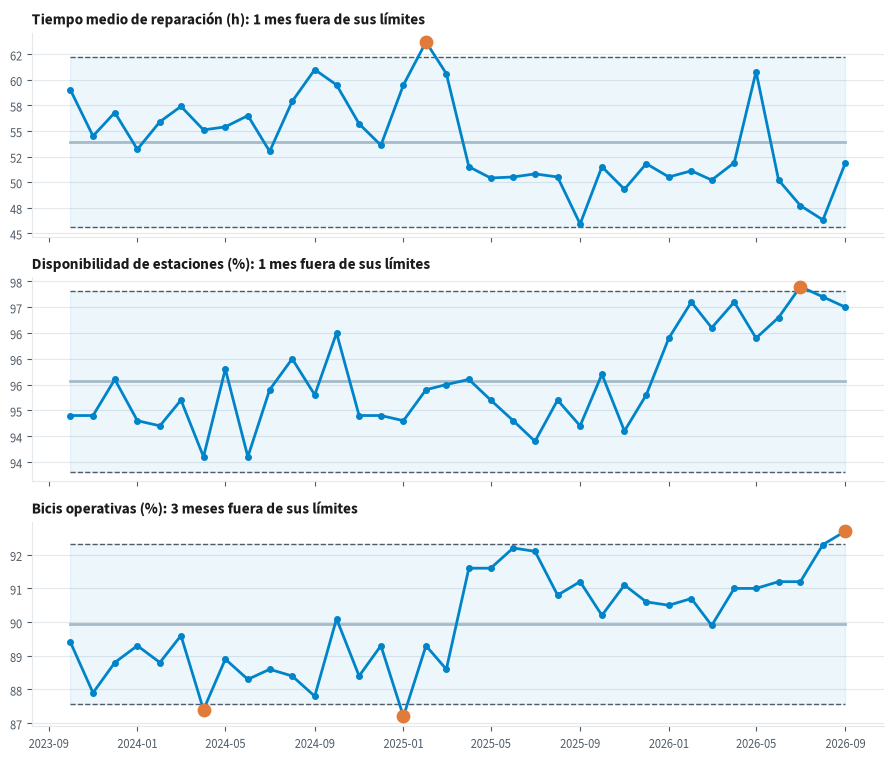

In [13]:
titulos = {"tmr_horas": "Tiempo medio de reparación (h)", "disponibilidad_pct": "Disponibilidad de estaciones (%)",
           "bicis_operativas_pct": "Bicis operativas (%)"}
fig, ejes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for ax, (nombre, tabla) in zip(ejes, resultados.items()):
    meses = tabla.index.to_timestamp()
    ax.fill_between(meses, tabla["lci"], tabla["lcs"], step="mid", color=estilo.AZUL, alpha=0.07)
    ax.step(meses, tabla["lci"], where="mid", color=estilo.TEXTO_2, linestyle="--", linewidth=1)
    ax.step(meses, tabla["lcs"], where="mid", color=estilo.TEXTO_2, linestyle="--", linewidth=1)
    ax.step(meses, tabla["media"], where="mid", color=estilo.GRIS, linewidth=2)
    ax.plot(meses, tabla["valor"], color=estilo.AZUL, marker="o", markersize=4)
    ax.scatter(meses[tabla["fuera"]], tabla["valor"][tabla["fuera"]], s=80, color=estilo.NARANJA, zorder=5)
    k = int(tabla["fuera"].sum())
    ax.set_title(f"{titulos[nombre]}: {k} {'mes' if k == 1 else 'meses'} fuera de sus límites",
                 fontsize=11, pad=6)
    estilo.formato_eje(ax, decimales=0)
plt.show()

**El umbral de alerta.** Una propuesta frecuente es «alerta si el indicador empeora más de un 10 %
frente al mes anterior». Probadla contra los 36 meses del tiempo de reparación y comparadla con el
límite superior de vuestro XmR: ¿cuántas alertas habría dado cada una, y cuántas tenían causa?

In [14]:
SUBIDA_ALERTA = 0.10   # ← «alerta si sube más de un 10 % frente al mes anterior»

reparacion = indicadores["tmr_horas"]
alerta_porcentaje = reparacion.pct_change() > SUBIDA_ALERTA
alerta_xmr = resultados["tmr_horas"]["valor"] > resultados["tmr_horas"]["lcs"]
print(f"«Sube más de un {pct(SUBIDA_ALERTA, 0)}»: {int(alerta_porcentaje.sum())} alertas: "
      + ", ".join(str(m) for m in reparacion.index[alerta_porcentaje]))
print(f"Por encima del límite superior del XmR: {int(alerta_xmr.sum())} alerta(s): "
      + (", ".join(str(m) for m in reparacion.index[alerta_xmr]) or "ninguna"))

«Sube más de un 10 %»: 4 alertas: 2025-01, 2025-10, 2026-05, 2026-09
Por encima del límite superior del XmR: 1 alerta(s): 2025-02


## 7. Volvamos a la pregunta: ¿y el +12 % de septiembre?

Con vuestros tramos del tiempo de reparación, ¿dónde cae septiembre de 2026?

In [15]:
t = resultados["tmr_horas"]
sep = t.loc[pd.Period("2026-09", "M")]
print(f"Septiembre de 2026: {n(sep['valor'], 1)} h; límites de su tramo {n(sep['lci'], 1)} a {n(sep['lcs'], 1)} h "
      f"(media {n(sep['media'], 1)} h) → {'FUERA: señal' if sep['fuera'] else 'dentro: ruido'}")

Septiembre de 2026: 51,9 h; límites de su tramo 45,6 a 62,3 h (media 53,9 h) → dentro: ruido


## Qué os lleváis

- Toda variación es **común** (del sistema) o **especial** (con nombre y fecha). Solo la segunda pide
  investigar; reaccionar a la primera empeora el proceso, como el embudo.
- **XmR:** media ± 2,66 × rango móvil medio. Los límites son la voz del proceso, no un deseo.
- **Pocas reglas**, decididas antes: cada regla de más adelanta las falsas alarmas.
- **Fase I** para fijar los límites y **fase II** para vigilar. Recalcular solo tras un cambio de
  proceso documentado.
- **Límite no es objetivo.** Si el objetivo cae fuera de los límites, hay que cambiar el proceso.
- Y la respuesta a la pregunta: la subida del 12 % está dentro de los límites; investigarla habría
  sido trabajo sin retorno. Mayo de 2026, en cambio, sí merecía la reunión.